# E-commerce A/B Testing Analysis

## Does the New Landing Page Improve Conversion?

## 1. Business Problem

An e-commerce company wants to improve its website's conversion performance. The company currently uses an existing landing page but has developed a new version that it believes may encourage more users to convert.

To evaluate the effectiveness of the new design, users were assigned to two different groups and exposed to different versions of the landing page.

The company now needs to determine whether the new landing page actually improves conversion performance.

---

## 2. Business Question

> **Should the company replace the existing landing page with the new landing page?**

This decision will not be based solely on which group has a higher conversion rate. The analysis will also consider statistical significance, confidence intervals, effect size, and practical business impact.

---

## 3. Experiment Overview

The experiment consists of two groups:

| Group | Landing Page | Purpose |
|---|---|---|
| **Control** | Old Landing Page | Current user experience / baseline |
| **Treatment** | New Landing Page | New version being tested |

Users in each group are compared based on whether they successfully converted.

---

## 4. Primary Metric

### Conversion Rate

The primary success metric for this experiment is the **conversion rate**.

$$
\text{Conversion Rate} =
\frac{\text{Number of Converted Users}}{\text{Total Number of Users}}
$$

In the dataset:

- **1** → User converted
- **0** → User did not convert

The main objective is to compare the conversion rates of the control and treatment groups.

---

## 5. Hypotheses

### Null Hypothesis ($H_0$)

The new landing page does not improve the conversion rate compared with the existing landing page.

### Alternative Hypothesis ($H_1$)

The new landing page improves the conversion rate compared with the existing landing page.



## Import libraries


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

## Load Dataset

In [2]:
ab_test = pd.read_csv("../data/raw/ab_data.csv")
countries = pd.read_csv("../data/raw/countries.csv")

In [ ]:
ab_test.head()

In [ ]:
countries.head()

## Basic Data Inspection

In [6]:
ab_test.shape

(294480, 5)

In [5]:
ab_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294480 entries, 0 to 294479
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294480 non-null  int64 
 1   timestamp     294480 non-null  object
 2   group         294480 non-null  object
 3   landing_page  294480 non-null  object
 4   converted     294480 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB


In [7]:
ab_test.describe()

,user_id,converted
count,294480.000000,294480.000000
mean,787973.538896,0.119658
std,91210.917091,0.324562
min,630000.000000,0.000000
25%,709031.750000,0.000000
50%,787932.500000,0.000000
75%,866911.250000,0.000000
max,945999.000000,1.000000


In [8]:
ab_test.isnull().sum()

user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64

In [9]:
countries.isnull().sum()

user_id    0
country    0
dtype: int64

In [10]:
ab_test.duplicated().sum()

np.int64(0)

In [11]:
ab_test["user_id"].duplicated().sum()

np.int64(3895)

In [12]:
ab_test["group"].value_counts()

group
treatment    147278
control      147202
Name: count, dtype: int64

In [13]:
ab_test["landing_page"].value_counts()

landing_page
new_page    147241
old_page    147239
Name: count, dtype: int64

In [14]:
ab_test["converted"].value_counts()

converted
0    259243
1     35237
Name: count, dtype: int64

In [15]:
pd.crosstab(
    ab_test["group"],
    ab_test["landing_page"]
)

landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145313,1965


### Findings

* The main **A/B testing dataset** contains **294,480 rows and 5 columns**.
* The `timestamp` column is stored as an object. Since time-based analysis is outside the scope of this project, no conversion was required.
* Neither dataset contains missing values.
* No fully duplicated rows were found. However, `user_id` contains **3,895 duplicated users**, requiring further investigation.
* The experiment population is nearly evenly distributed between the **control (147,202)** and **treatment (147,278)** groups.
* There are **35,237 converted users (1)** and **259,243 non-converted users (0)**.
* Most users were assigned to the expected landing page: the **control group** primarily received the `old_page`, while the **treatment group** primarily received the `new_page`. However, a small number of users were assigned inconsistently, which required further investigation.

| Group     | New Page | Old Page |
| --------- | -------: | -------: |
| Control   |    1,928 |  145,274 |
| Treatment |  145,313 |    1,965 |



## Data Quality Investigation

In [23]:
duplicate_users = ab_test[
    ab_test["user_id"].duplicated(keep=False)
].sort_values("user_id")



In [17]:
duplicate_users.shape

(7790, 5)

In [ ]:
duplicate_users.head(20).reset_index(drop=True)

In [ ]:
duplicate_users.groupby("user_id")[["group", "landing_page"]].nunique()

In [21]:
duplicate_users.groupby("user_id")["group"].nunique().value_counts()

group
1    2000
2    1895
Name: count, dtype: int64

In [22]:
duplicate_users.groupby("user_id")["landing_page"].nunique().value_counts()

landing_page
2    1998
1    1897
Name: count, dtype: int64

In [24]:
mismatch = (
    ((ab_test["group"] == "control") &
     (ab_test["landing_page"] == "new_page"))
    |
    ((ab_test["group"] == "treatment") &
     (ab_test["landing_page"] == "old_page"))
)

In [25]:
ab_test[mismatch].shape

(3893, 5)

In [26]:
mismatched_data = ab_test[mismatch]

mismatched_data["user_id"].duplicated(keep=False).sum()

np.int64(0)

In [27]:
mismatched_data["user_id"].isin(
    duplicate_users["user_id"]
).all()

np.True_

In [28]:
duplicate_user_ids = duplicate_users["user_id"].unique()

mismatched_user_ids = mismatched_data["user_id"].unique()

duplicate_users_without_mismatch = set(duplicate_user_ids) - set(mismatched_user_ids)

duplicate_users_without_mismatch

{np.int64(759899), np.int64(773192)}

In [29]:
ab_test[
    ab_test["user_id"].isin(duplicate_users_without_mismatch)
].sort_values("user_id")

,user_id,timestamp,group,landing_page,converted
294478,759899,20:29.0,treatment,new_page,0
250001,759899,07:36.1,treatment,new_page,0
2893,773192,55:59.6,treatment,new_page,0
1899,773192,37:58.8,treatment,new_page,0


## Data Quality Investigation-Findings

During the initial data inspection, duplicate user records and inconsistencies between the assigned experiment group and landing page were identified. Before performing the A/B test, these issues were investigated to understand their relationship.

### Duplicate Users

The dataset contains **3,895 duplicated user IDs**. Since each duplicated user appears twice, this results in **7,790 rows associated with duplicated users**.

Further inspection showed that these were not simply identical duplicate rows. Some users appeared with different experimental assignments or different landing pages.

### Group and Landing Page Mismatches

A valid A/B test should follow the expected assignment:

* **Control group → Old page**
* **Treatment group → New page**

However, **3,893 records** did not follow this expected relationship:

* Control users assigned to the **new page**
* Treatment users assigned to the **old page**

### Relationship Between Duplicate Users and Mismatches

Further investigation confirmed that **all 3,893 mismatched records belonged to users with duplicate IDs**.

For most duplicated users, one record followed the expected experiment assignment while another record contained an inconsistent group or landing page assignment.

The remaining **two duplicated users** had consistent records, appearing twice in the treatment group and receiving the new page both times.

### Conclusion

The investigation shows that duplicate user records are closely related to the inconsistencies found in the experiment assignments.

Since a reliable A/B test requires each user to have a clear and valid experimental assignment, the data needs to be cleaned before comparing conversion rates or performing statistical hypothesis testing.

The next step is to retain only valid group-to-page assignments and ensure that each user is represented only once in the final analysis dataset.


## Data Cleaning

In [30]:
valid_data = ab_test[
    ((ab_test["group"] == "control") & 
     (ab_test["landing_page"] == "old_page")) |
    
    ((ab_test["group"] == "treatment") & 
     (ab_test["landing_page"] == "new_page"))
].copy()

In [31]:
valid_data.shape

(290587, 5)

In [32]:
valid_data["user_id"].duplicated().sum()

np.int64(2)

In [ ]:
valid_data[
    valid_data["user_id"].duplicated(keep=False)
].sort_values("user_id")

In [34]:
clean_data = valid_data.drop_duplicates(
    subset="user_id",
    keep="first"
).copy()

In [35]:
clean_data.shape

(290585, 5)

In [36]:
clean_data["user_id"].nunique()

290585

In [37]:
clean_data["user_id"].duplicated().sum()

np.int64(0)

In [38]:
pd.crosstab(
    clean_data["group"],
    clean_data["landing_page"]
)

landing_page,new_page,old_page
group,,
control,0,145274
treatment,145311,0


### Data Cleaning Summary

The data quality investigation identified duplicate users and invalid group-to-page assignments.

For a valid A/B test:

* **Control → Old Page**
* **Treatment → New Page**
* Each user should appear only once

### Cleaning Steps

1. Removed records with mismatched group and landing page assignments.
2. Removed the remaining duplicate users.

### Final Validation

The cleaned dataset contains:

* No duplicate users
* Valid group-to-page assignments
* One record per user

The final `clean_data` dataset will be used for the remaining analysis and statistical testing.


In [57]:
clean_data.to_csv(
    "../data/processed/clean_ab_data.csv",
    index=False
)

## Experiment Validation

In [39]:
clean_data["group"].value_counts()

group
treatment    145311
control      145274
Name: count, dtype: int64

In [40]:
clean_data["group"].value_counts(normalize=True)

group
treatment    0.500064
control      0.499936
Name: proportion, dtype: float64

In [41]:
group_summary = clean_data["group"].value_counts().reset_index()

group_summary.columns = ["Group", "Users"]

group_summary

,Group,Users
0,treatment,145311
1,control,145274


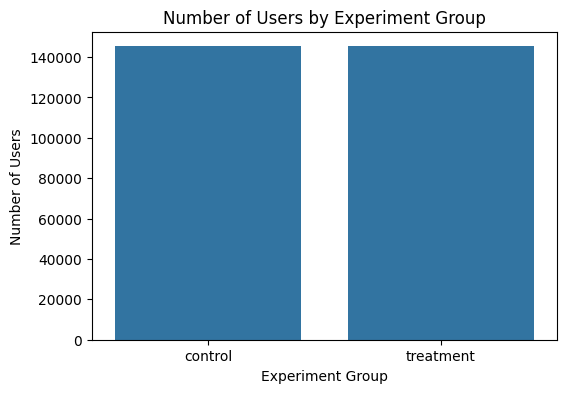

In [42]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=clean_data,
    x="group"
)

plt.title("Number of Users by Experiment Group")
plt.xlabel("Experiment Group")
plt.ylabel("Number of Users")

plt.show()

### Finding

The user population is reasonably balanced between the control and treatment groups, with both groups containing approximately **50% of the total users**.

This suggests that the experiment allocation appears balanced and there is no obvious imbalance in sample sizes between the two groups.


### SRM (Sample Ratio Mismatch) 

In [43]:
observed = clean_data["group"].value_counts()

observed

group
treatment    145311
control      145274
Name: count, dtype: int64

In [44]:
from scipy.stats import chisquare

observed = clean_data["group"].value_counts()

expected = [
    len(clean_data) / 2,
    len(clean_data) / 2
]

chi2, p_value = chisquare(
    f_obs=observed,
    f_exp=expected
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")

Chi-square statistic: 0.0047
P-value: 0.9453


### SRM Result

The SRM test found **no statistically significant difference** between the observed and expected 50/50 group allocation (**p-value > 0.05**).

This suggests the experiment groups are reasonably balanced and there is **no significant evidence of Sample Ratio Mismatch**.


## Conversion Analysis


In [47]:
conversion_summary = clean_data.groupby("group").agg(
    users=("user_id", "count"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean")
)
conversion_summary["conversion_rate"] = (
    conversion_summary["conversion_rate"] * 100
)
conversion_summary

,users,conversions,conversion_rate
group,,,
control,145274,17489,12.038630
treatment,145311,17264,11.880725


In [48]:
control_rate = conversion_summary.loc["control", "conversion_rate"]

treatment_rate = conversion_summary.loc["treatment", "conversion_rate"]

difference = treatment_rate - control_rate

print(f"Control Conversion Rate: {control_rate:.2f}%")
print(f"Treatment Conversion Rate: {treatment_rate:.2f}%")
print(f"Difference: {difference:.2f} percentage points")

Control Conversion Rate: 12.04%
Treatment Conversion Rate: 11.88%
Difference: -0.16 percentage points


In [49]:
relative_uplift = (
    (treatment_rate - control_rate) / control_rate
) * 100

print(f"Relative Uplift: {relative_uplift:.2f}%")

Relative Uplift: -1.31%


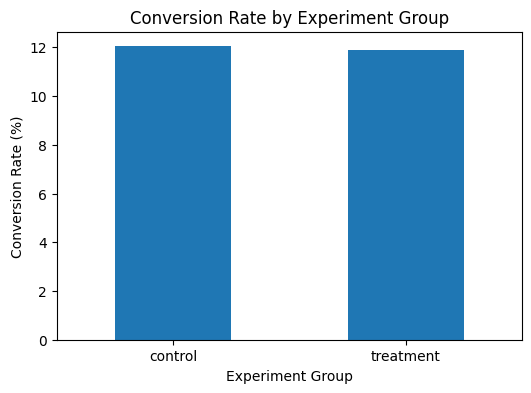

In [50]:
conversion_summary["conversion_rate"].plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Conversion Rate by Experiment Group")
plt.xlabel("Experiment Group")
plt.ylabel("Conversion Rate (%)")

plt.xticks(rotation=0)

plt.show()

### Conversion Analysis Findings

The control group had a conversion rate of **12.04%**, compared with **11.88%** for the treatment group.

This represents an observed difference of **-0.16 percentage points** and a **-1.31% relative uplift**, suggesting that the new landing page performed slightly worse than the existing page.

However, statistical testing is required to determine whether this difference is statistically significant or could be explained by random variation.


## Hypothesis Testing

In [53]:
from statsmodels.stats.proportion import proportions_ztest

conversions = np.array([
    clean_data.loc[clean_data["group"] == "control", "converted"].sum(),
    clean_data.loc[clean_data["group"] == "treatment", "converted"].sum()
])

users = np.array([
    (clean_data["group"] == "control").sum(),
    (clean_data["group"] == "treatment").sum()
])

print("Conversions:", conversions)
print("Users:", users)

Conversions: [17489 17264]
Users: [145274 145311]


### Hypotheses

**Null Hypothesis (H₀):** The conversion rates of the control and treatment groups are equal.

**Alternative Hypothesis (H₁):** The conversion rates of the control and treatment groups are different.

A significance level of **α = 0.05** was used for the test.


In [54]:
z_stat, p_value = proportions_ztest(
    count=conversions,
    nobs=users,
    alternative="two-sided"
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.4f}")

Z-statistic: 1.3116
P-value: 0.1897


In [55]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Fail to reject the null hypothesis


### Hypothesis Testing Findings

A **two-proportion Z-test** was used to compare the conversion rates of the control and treatment groups.

Since the **p-value was greater than 0.05**, we failed to reject the null hypothesis.

This means there is insufficient statistical evidence to conclude that the conversion rates of the old and new landing pages are significantly different.


## Confidence Interval

In [56]:
import numpy as np
from statsmodels.stats.proportion import confint_proportions_2indep

control = clean_data[clean_data["group"] == "control"]
treatment = clean_data[clean_data["group"] == "treatment"]

count_control = control["converted"].sum()
nobs_control = len(control)

count_treatment = treatment["converted"].sum()
nobs_treatment = len(treatment)

lower, upper = confint_proportions_2indep(
    count1=count_treatment,
    nobs1=nobs_treatment,
    count2=count_control,
    nobs2=nobs_control,
    method="wald",
    compare="diff"
)

print(f"95% Confidence Interval: ({lower:.4%}, {upper:.4%})")

95% Confidence Interval: (-0.3939%, 0.0781%)


### Confidence Interval Analysis

The estimated difference between the treatment and control conversion rates was **−0.16 percentage points**.

The **95% confidence interval ranged from −0.39% to +0.08%**. Since the interval includes zero, the true effect could represent either a small decrease or a small increase in conversion.

This supports the hypothesis test result that there is no statistically significant difference between the two landing pages.


## Practical Significance

The dataset does not provide a business-defined threshold for a meaningful improvement. Therefore, a **0.5 percentage point increase in conversion** was used as an assumed practical threshold for demonstration purposes.

The observed difference was **−0.16 percentage points**, and the 95% confidence interval ranged from **−0.39% to +0.08%**.

Even the most optimistic plausible improvement is below the assumed **0.5 percentage point threshold**, suggesting that the new landing page does not demonstrate a meaningful business improvement.


## Secondary Analysis - Country level

This analysis is exploratory and secondary to the primary A/B test.

In [58]:
analysis_data = clean_data.merge(
    countries,
    on="user_id",
    how="left"
)

analysis_data.head()

,user_id,timestamp,group,landing_page,converted,country
0,851104,11:48.6,control,old_page,0,US
1,804228,01:45.2,control,old_page,0,US
2,661590,55:06.2,treatment,new_page,0,US
3,853541,28:03.1,treatment,new_page,0,US
4,864975,52:26.2,control,old_page,1,US


In [59]:
analysis_data["country"].isnull().sum()

np.int64(0)

In [60]:
analysis_data["country"].value_counts()

country
US    203621
UK     72466
CA     14499
Name: count, dtype: int64

In [ ]:
country_summary = analysis_data.groupby(
    ["country", "group"]
).agg(
    users=("user_id", "count"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean")
).reset_index()

country_summary["conversion_rate"] *= 100

country_summary

In [62]:
country_pivot = country_summary.pivot(
    index="country",
    columns="group",
    values="conversion_rate"
)

country_pivot["difference_pp"] = (
    country_pivot["treatment"] - country_pivot["control"]
)

country_pivot

group,control,treatment,difference_pp
country,,,
CA,11.878300,11.190248,-0.688052
UK,12.002200,12.117100,0.114899
US,12.062999,11.846327,-0.216671


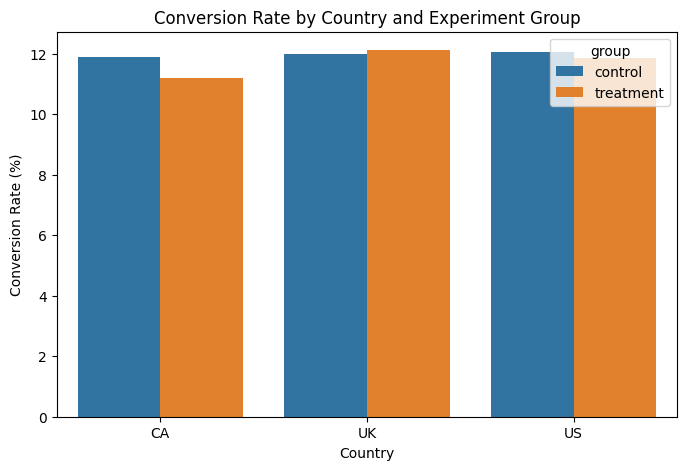

In [66]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=country_summary,
    x="country",
    y="conversion_rate",
    hue="group"
)

plt.title("Conversion Rate by Country and Experiment Group")
plt.xlabel("Country")
plt.ylabel("Conversion Rate (%)")

plt.show()

### Country-Level Statistical Testing

Since conversion rates are being compared across three countries, multiple statistical tests are performed. To reduce the risk of false positives, the Bonferroni correction is applied.

With three comparisons:

$$
\alpha_{adjusted} = \frac{0.05}{3} = 0.0167
$$

A country-level result is considered statistically significant only if its p-value is below **0.0167**.


In [63]:
from statsmodels.stats.proportion import proportions_ztest

def country_ztest(data, country):
    
    country_data = data[data["country"] == country]
    
    conversions = [
        country_data.loc[
            country_data["group"] == "control", "converted"
        ].sum(),
        
        country_data.loc[
            country_data["group"] == "treatment", "converted"
        ].sum()
    ]
    
    users = [
        (country_data["group"] == "control").sum(),
        (country_data["group"] == "treatment").sum()
    ]
    
    z_stat, p_value = proportions_ztest(
        count=conversions,
        nobs=users,
        alternative="two-sided"
    )
    
    return z_stat, p_value

In [64]:
for country in analysis_data["country"].unique():
    
    z_stat, p_value = country_ztest(analysis_data, country)
    
    print(f"{country}")
    print(f"Z-statistic: {z_stat:.4f}")
    print(f"P-value: {p_value:.4f}")
    print("-" * 30)

US
Z-statistic: 1.5068
P-value: 0.1319
------------------------------
CA
Z-statistic: 1.2969
P-value: 0.1947
------------------------------
UK
Z-statistic: -0.4749
P-value: 0.6349
------------------------------


In [65]:
alpha = 0.05
adjusted_alpha = alpha / 3

print(f"Bonferroni-adjusted alpha: {adjusted_alpha:.4f}")

Bonferroni-adjusted alpha: 0.0167


### Country-Level Analysis

A secondary analysis was performed to examine whether the experiment results differed across the US, UK, and Canada.

While the observed conversion differences varied by country, none of the country-level tests were statistically significant after applying the Bonferroni-adjusted significance level (**α = 0.0167**).

Therefore, there is insufficient evidence to conclude that the new landing page had a significantly different effect on conversion in any individual country.


## Key Insights

* The experiment groups were reasonably balanced, with no significant evidence of Sample Ratio Mismatch.
* The control group had a slightly higher conversion rate (**12.04%**) than the treatment group (**11.88%**).
* The observed difference was **−0.16 percentage points**, indicating slightly lower conversion for the new landing page.
* The two-proportion Z-test found no statistically significant difference between the groups.
* The 95% confidence interval (**−0.39% to +0.08%**) included zero, meaning the true effect could be either a small decrease or a small increase.
* Based on the assumed practical significance threshold, the experiment did not demonstrate a meaningful improvement in conversion.
* Country-level analysis showed varying observed results across the US, UK, and Canada, but none of the differences were statistically significant after applying the Bonferroni correction.

## Recommendation

Based on the A/B test results, the new landing page should **not be implemented as a replacement for the existing page at this time**.

Although the treatment group showed a slightly lower conversion rate (**11.88%**) compared to the control group (**12.04%**), the difference of **−0.16 percentage points** was not statistically significant.

The SRM check found no significant imbalance in group allocation, and the 95% confidence interval (**−0.39% to +0.08%**) included zero. This means the observed difference could reasonably be explained by random variation.

Additionally, even the most optimistic plausible improvement was below the assumed practical significance threshold of **0.5 percentage points**.

Country-level analysis also found no statistically significant treatment effect in the US, UK, or Canada.

### Business Decision

**Do not roll out the new landing page based on the current experiment results.**

The company should retain the existing landing page and consider testing a redesigned version with a clearer hypothesis or stronger expected improvement.


## Limitations


* The dataset does not include additional user attributes or behavioral data, limiting deeper segmentation analysis.
* The **0.5 percentage point practical significance threshold** was assumed for demonstration purposes and was not based on actual business requirements.
* The analysis focuses primarily on conversion and does not consider other business metrics such as revenue, engagement, or long-term user behavior.
* The country-level analysis was conducted as a **secondary exploratory analysis**, so its results should be interpreted cautiously.

